Réalisé par : Abdelkader Arras

### Cnn classification model

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

### Step1. dataset

In [3]:
img_height,img_width = 32,32
batch_size = 20
train_dataset=tf.keras.utils.image_dataset_from_directory("fruits/fruits/train",image_size=(img_height,img_width),batch_size=batch_size)
test_dataset=tf.keras.utils.image_dataset_from_directory("fruits/fruits/test",image_size=(img_height,img_width),batch_size=batch_size)
validation_dataset=tf.keras.utils.image_dataset_from_directory("fruits/fruits/validation",image_size=(img_height,img_width),batch_size=batch_size)



Found 460 files belonging to 3 classes.
Found 130 files belonging to 3 classes.
Found 66 files belonging to 3 classes.


### Step2. dataset visulisation

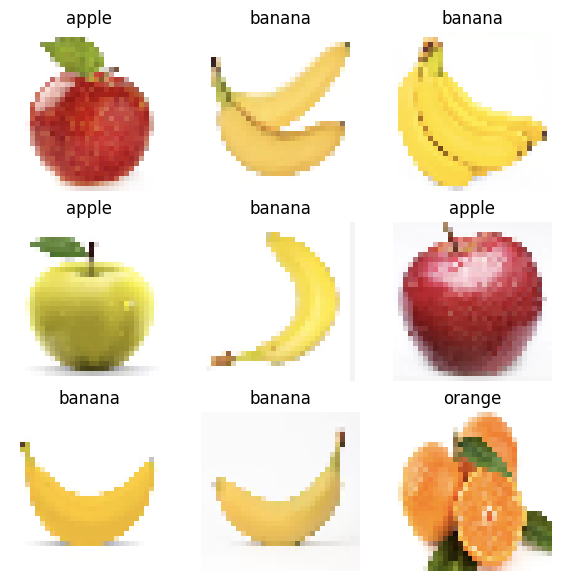

In [4]:
class_names=train_dataset.class_names
plt.figure(figsize=(7,7))
for image,labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

### Step3. Creation du modele

In [5]:
model=tf.keras.Sequential(
    [
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(32,(3,3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32,(3,3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32,(3,3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(3,activation="softmax"),
    ])


### Step4. model parameters

In [6]:
model.compile(optimizer="adam",loss="SparseCategoricalCrossentropy",metrics=["accuracy"])

### Step4. training model

In [7]:
model.fit(train_dataset,validation_data=validation_dataset,epochs=10)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.5848 - loss: 0.8514 - val_accuracy: 0.8333 - val_loss: 0.4942
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.8109 - loss: 0.4723 - val_accuracy: 0.7879 - val_loss: 0.6736
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.8674 - loss: 0.3468 - val_accuracy: 0.8788 - val_loss: 0.4087
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.8957 - loss: 0.2913 - val_accuracy: 0.9242 - val_loss: 0.2702
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.8957 - loss: 0.2717 - val_accuracy: 0.8788 - val_loss: 0.3544
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9500 - loss: 0.1895 - val_accuracy: 0.8485 - val_loss: 0.3666
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9326 - loss: 0.1943 - val_accuracy: 0.9242 - val_loss: 0.2007
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9457 - loss: 0.1501 - val_accuracy: 0.9394 - v

In [8]:
model.evaluate(test_dataset,verbose=2)

7/7 - 0s - 40ms/step - accuracy: 0.9077 - loss: 0.1770


[0.17701731622219086, 0.9076923131942749]

In [11]:
lass_names=train_dataset.class_names
print("--- Actual Class Names Order ---")
print(class_names)
print("--------------------------------")

--- Actual Class Names Order ---
['apple', 'banana', 'orange']
--------------------------------


In [10]:
for images, labels in test_dataset.take(1):
    predictions = model.predict(images)
    predicted_classes = np.argmax(predictions, axis=1)
    #print(predicted_classes)

    for i in range(len(images)):
        true_label = test_dataset.class_names[labels[i]]
        predicted_label = test_dataset.class_names[predicted_classes[i]]
        print(f"Image {i+1}: Réelle = {true_label},  Prédite = {predicted_label}")



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Image 1: Réelle = orange,  Prédite = apple
Image 2: Réelle = orange,  Prédite = orange
Image 3: Réelle = apple,  Prédite = banana
Image 4: Réelle = banana,  Prédite = banana
Image 5: Réelle = orange,  Prédite = orange
Image 6: Réelle = apple,  Prédite = apple
Image 7: Réelle = apple,  Prédite = banana
Image 8: Réelle = apple,  Prédite = apple
Image 9: Réelle = banana,  Prédite = banana
Image 10: Réelle = banana,  Prédite = banana
Image 11: Réelle = apple,  Prédite = apple
Image 12: Réelle = orange,  Prédite = orange
Image 13: Réelle = apple,  Prédite = apple
Image 14: Réelle = orange,  Prédite = orange
Image 15: Réelle = orange,  Prédite = orange
Image 16: Réelle = apple,  Prédite = apple
Image 17: Réelle = orange,  Prédite = orange
Image 18: Réelle = banana,  Prédite = banana
Image 19: Réelle = banana,  Prédite = banana
Image 20: Réelle = orange,  Prédite = orange


In [15]:
model.save('CNN_Fruits_Classification.h5')